# 0. Imports

In [27]:
import matplotlib.pyplot as plt  # Plot training results
import torch                     # Tensors and training
from torch import nn             # Neural network layers and loss functions
from torch_geometric.datasets import Planetoid  # Load Cora

from copy import deepcopy

import json
from pathlib import Path

import sys
sys.path.append("..")  # Makes the project folder importable


# 1. Load the data

In [28]:
dataset = Planetoid(root="../data", name="Cora")
graph = dataset[0]

In [29]:
# Training data
X_train = graph.x[graph.train_mask]
y_train = graph.y[graph.train_mask]

# Validation data
X_val = graph.x[graph.val_mask]
y_val = graph.y[graph.val_mask]

# Test data
X_test = graph.x[graph.test_mask]
y_test = graph.y[graph.test_mask]

X_train.shape, X_val.shape, X_test.shape

(torch.Size([140, 1433]), torch.Size([500, 1433]), torch.Size([1000, 1433]))

# 2. MLP baseline model

In [30]:
from src.models import MLP

model = MLP(
	input_dim=dataset.num_node_features,
	hidden_dim=64,
	num_classes=dataset.num_classes
)

In [ ]:
seed = 42
torch.manual_seed(seed)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

epochs = 200

best_val_accuracy = -1.0
best_state = None
best_epoch = None

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

for epoch in range(1, epochs + 1):
	# Training
	model.train()
	optimizer.zero_grad()

	logits = model(X_train)
	loss = criterion(logits, y_train)

	loss.backward()   # Calculate gradients
	optimizer.step()  # Update model weights

	# Validation: no gradients or weight updates
	model.eval()
	with torch.no_grad():
		val_logits = model(X_val)
		val_loss = criterion(val_logits, y_val)

		val_predictions = val_logits.argmax(dim=1)
		val_accuracy = (val_predictions == y_val).float().mean().item()

		train_losses.append(loss.item())
		val_losses.append(val_loss.item())

		train_accuracy = (logits.argmax(dim=1) == y_train).float().mean().item()
		train_accuracies.append(train_accuracy)
		val_accuracies.append(val_accuracy)

		if val_accuracy > best_val_accuracy:
			best_val_accuracy = val_accuracy
			best_state = deepcopy(model.state_dict())
			best_epoch = epoch

	if epoch == 1 or epoch % 20 == 0:
		print(
			f"Epoch {epoch:3d} | "
			f"Train loss: {loss.item():.4f} | "
			f"Val loss: {val_loss.item():.4f} | "
			f"Val accuracy: {val_accuracy:.1%}"
		)

print(f"Best epoch: {best_epoch} | Val accuracy: {best_val_accuracy:.1%}")

Epoch   1 | Train loss: 1.9506 | Val loss: 1.8989 | Val accuracy: 33.8%
Epoch  20 | Train loss: 0.0090 | Val loss: 1.5479 | Val accuracy: 55.2%
Epoch  40 | Train loss: 0.0005 | Val loss: 2.1334 | Val accuracy: 51.4%
Epoch  60 | Train loss: 0.0002 | Val loss: 2.2778 | Val accuracy: 50.6%
Epoch  80 | Train loss: 0.0002 | Val loss: 2.3110 | Val accuracy: 50.4%
Epoch 100 | Train loss: 0.0001 | Val loss: 2.3249 | Val accuracy: 50.2%
Epoch 120 | Train loss: 0.0001 | Val loss: 2.3349 | Val accuracy: 50.2%
Epoch 140 | Train loss: 0.0001 | Val loss: 2.3434 | Val accuracy: 50.2%
Epoch 160 | Train loss: 0.0001 | Val loss: 2.3508 | Val accuracy: 50.2%
Epoch 180 | Train loss: 0.0001 | Val loss: 2.3573 | Val accuracy: 50.0%
Epoch 200 | Train loss: 0.0001 | Val loss: 2.3631 | Val accuracy: 50.0%
Best epoch: 11 | Val accuracy: 58.0%


In [32]:
model.load_state_dict(best_state)
model.eval()

with torch.no_grad():
    test_logits = model(X_test)
    test_predictions = test_logits.argmax(dim=1)
    test_accuracy = (test_predictions == y_test).float().mean().item()

print(f"Test accuracy: {test_accuracy:.1%}")

Test accuracy: 54.7%


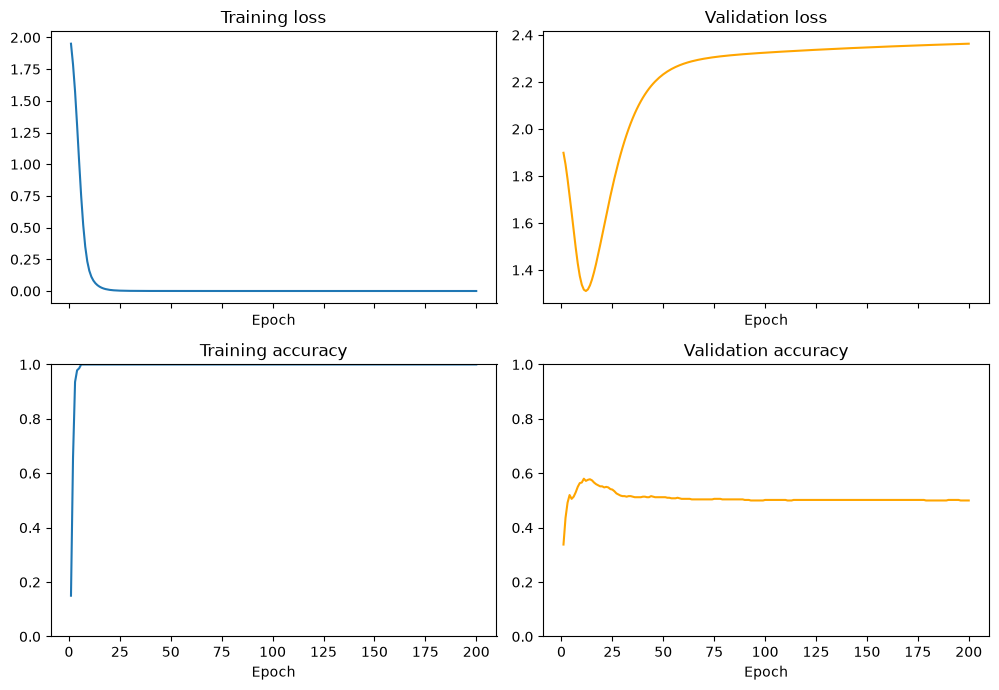

In [35]:
results_dir = Path("../results") / type(model).__name__
results_dir.mkdir(parents=True, exist_ok=True)

results = {
    "model": type(model).__name__,
    "learning_rate": optimizer.param_groups[0]["lr"],
    "best_epoch": best_epoch,
    "val_accuracy": best_val_accuracy,
    "test_accuracy": test_accuracy,
}

file_path = results_dir / f"{results['model']}.json"

file_path.write_text(json.dumps(results, indent=2), encoding="utf-8")

epoch_numbers = range(1, len(train_losses) + 1)

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)

axes[0, 0].plot(epoch_numbers, train_losses)
axes[0, 0].set_title("Training loss")

axes[0, 1].plot(epoch_numbers, val_losses, color="orange")
axes[0, 1].set_title("Validation loss")

axes[1, 0].plot(epoch_numbers, train_accuracies)
axes[1, 0].set_title("Training accuracy")
axes[1, 0].set_ylim(0, 1)

axes[1, 1].plot(epoch_numbers, val_accuracies, color="orange")
axes[1, 1].set_title("Validation accuracy")
axes[1, 1].set_ylim(0, 1)

for ax in axes.flat:
    ax.set_xlabel("Epoch")

plt.tight_layout()
fig.savefig(results_dir / "training.png", dpi=150)
plt.show()